## Nome: Caio Semblano Silva
## Matrícula: 621
-----


# **ATV 12 — Organização de Dados**

Esta atividade pratica a **organização e a apresentação de dados** em Estatística: classificação de variáveis, distribuições de frequências (qualitativas, quantitativas discretas e contínuas agrupadas em classes), representações gráficas e tabelas de contingência.

**Objetivos**
- Classificar variáveis (tipo e escala de medida).
- Construir **tabelas de frequências** (fi, fr, fr%, Fac, xi) para cada tipo de variável.
- Agrupar dados contínuos em classes (regra de **Sturges**, amplitude, intervalo de classe).
- Construir **gráficos** adequados: barras, setores, bastões, histograma, polígono de frequências.


## Instruções gerais

- Execute as células na ordem em que aparecem.
- Sempre **identifique o tipo da variável** antes de escolher a tabela e o gráfico.
- Ferramentas úteis:
  - `Series.value_counts()` → frequências absolutas (`sort_index()` para ordenar pelos valores);
  - `Series.cumsum()` → frequências acumuladas;
  - `plt.bar`, `plt.pie`, `plt.stem`, `plt.step` → gráficos.


In [1]:
# Imports úteis para toda a atividade
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)



## Exercício 1 — **Classificação de variáveis** (tipo e escala)

**Contexto**: Um hospital registra, para cada paciente atendido, as variáveis abaixo.

| # | **Variável**                                         | **Exemplo de valor**        |
|:-:|------------------------------------------------------|-----------------------------|
| 1 | Sexo                                                 | F                           |
| 2 | Tipo sanguíneo                                       | AB                          |
| 3 | Grau de escolaridade (fundamental, médio, superior)  | Médio                       |
| 4 | Número de filhos                                     | 2                           |
| 5 | Altura (cm)                                          | 168,5                       |
| 6 | Temperatura corporal (°C)                            | 36,8                        |
| 7 | Satisfação (ruim, regular, boa, ótima)               | Boa                         |
| 8 | Número de internações nos últimos 5 anos             | 0                           |
| 9 | Estado civil                                         | Casado(a)                   |
| 10 | Tempo de espera no pronto-atendimento (min)         | 37                          |

1. Classifique cada variável como **qualitativa nominal**, **qualitativa ordinal**, **quantitativa discreta** ou **quantitativa contínua**.
2. Informe a **escala de medida** de cada uma (nominal, ordinal, intervalar ou razão).
3. Organize a classificação em um `DataFrame` (colunas *Tipo* e *Escala*).
4. Conte quantas variáveis há em cada tipo.


In [3]:
classificacao = pd.DataFrame({
    "Variável": [
        "Sexo",
        "Tipo sanguíneo",
        "Grau de escolaridade",
        "Número de filhos",
        "Altura (cm)",
        "Temperatura corporal (°C)",
        "Satisfação",
        "Número de internações nos últimos 5 anos",
        "Estado civil",
        "Tempo de espera no pronto-atendimento (min)"
    ],
    "Tipo": [
        "Qualitativa nominal",
        "Qualitativa nominal",
        "Qualitativa ordinal",
        "Quantitativa discreta",
        "Quantitativa contínua",
        "Quantitativa contínua",
        "Qualitativa ordinal",
        "Quantitativa discreta",
        "Qualitativa nominal",
        "Quantitativa contínua"
    ],
    "Escala": [
        "Nominal",
        "Nominal",
        "Ordinal",
        "Razão",
        "Razão",
        "Intervalar",
        "Ordinal",
        "Razão",
        "Nominal",
        "Razão"
    ]
})

display(classificacao)
print()
print("Quantidade de variáveis por tipo:")
display(classificacao["Tipo"].value_counts())

,Variável,Tipo,Escala
0,Sexo,Qualitativa nominal,Nominal
1,Tipo sanguíneo,Qualitativa nominal,Nominal
2,Grau de escolaridade,Qualitativa ordinal,Ordinal
3,Número de filhos,Quantitativa discreta,Razão
4,Altura (cm),Quantitativa contínua,Razão
5,Temperatura corporal (°C),Quantitativa contínua,Intervalar
6,Satisfação,Qualitativa ordinal,Ordinal
7,Número de internações nos últimos 5 anos,Quantitativa discreta,Razão
8,Estado civil,Qualitativa nominal,Nominal
9,Tempo de espera no pronto-atendimento (min),Quantitativa contínua,Razão



Quantidade de variáveis por tipo:


Tipo
Qualitativa nominal      3
Quantitativa contínua    3
Qualitativa ordinal      2
Quantitativa discreta    2
Name: count, dtype: int64

**Conclusão:**

Das 10 variáveis, 3 são qualitativas nominais (sexo, tipo sanguíneo e estado civil), 2 ordinais (escolaridade e satisfação), 2 quantitativas discretas (filhos e internações) e 3 contínuas (altura, temperatura e tempo de espera).

A escala muda o que dá para calcular: nas nominais só faz sentido a moda; nas ordinais já entra a mediana; nas de razão dá para falar em média e em "o dobro". A temperatura em °C ficou como intervalar porque 0 °C é uma convenção, não ausência de calor. 40 °C não é o dobro de 20 °C. Já altura e tempo de espera têm zero absoluto, então são de razão.



## Exercício 2 — Distribuição de frequências de uma variável **qualitativa**

**Contexto**: Em uma campanha de doação, foi registrado o **tipo sanguíneo** de **n = 40** doadores. Os dados brutos estão na célula abaixo.

1. Identifique o tipo e a escala da variável.
2. Construa a **tabela de frequências** com **fi**, **fr** e **fr (%)**, ordenada de forma decrescente por fi.
3. Verifique que Σfi = n e Σfr = 1.
4. Construa um **gráfico de barras** (fi) e um **gráfico de setores** (%).
5. Indique a **moda** e conclua.


In [4]:
# Dados brutos — tipo sanguíneo de 40 doadores
sangue = pd.Series([
    'O', 'A', 'O', 'O', 'A', 'A', 'O', 'B', 'O', 'B',
    'O', 'O', 'O', 'B', 'AB', 'O', 'A', 'O', 'O', 'A',
    'O', 'B', 'O', 'B', 'A', 'A', 'A', 'AB', 'AB', 'O',
    'A', 'O', 'A', 'A', 'A', 'O', 'A', 'B', 'A', 'O'
], name="Tipo sanguíneo")


Variável: tipo sanguíneo
Tipo: qualitativa nominal
Escala: nominal



,fi,fr,fr (%)
Tipo sanguíneo,,,
O,17,0.425,42.5
A,14,0.350,35.0
B,6,0.150,15.0
AB,3,0.075,7.5



Soma de fi = 40  (n = 40 )
Soma de fr = 0.9999999999999999
Soma de fr (%) = 100.0
Moda: O com fi = 17 ( 42.5 %)


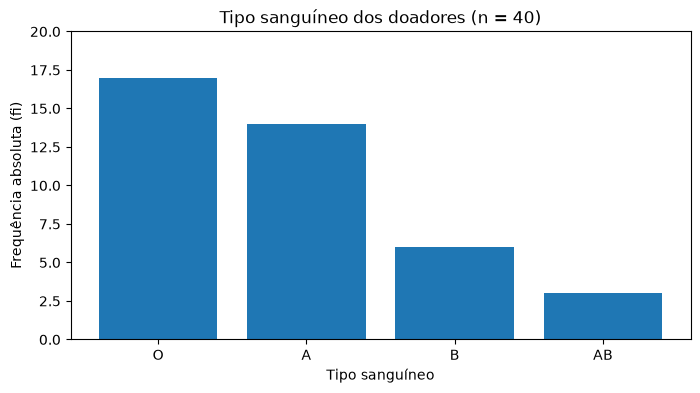

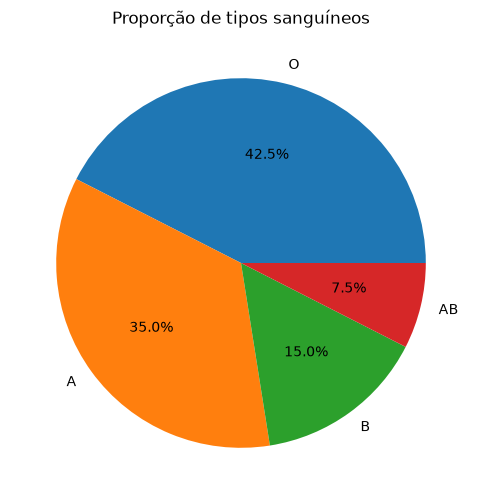

In [5]:
print("Variável: tipo sanguíneo")
print("Tipo: qualitativa nominal")
print("Escala: nominal")
print()

n = len(sangue)
fi = sangue.value_counts()
fr = sangue.value_counts(normalize=True)
fr_perc = fr * 100

tab_sangue = pd.DataFrame({
    "fi": fi,
    "fr": fr,
    "fr (%)": fr_perc
})
tab_sangue.index.name = "Tipo sanguíneo"

display(tab_sangue)
print()
print("Soma de fi =", tab_sangue["fi"].sum(), " (n =", n, ")")
print("Soma de fr =", tab_sangue["fr"].sum())
print("Soma de fr (%) =", tab_sangue["fr (%)"].sum())

moda = fi.idxmax()
print("Moda:", moda, "com fi =", fi.max(), "(", round(fr_perc[moda], 1), "%)")

plt.figure(figsize=(8, 4))
plt.bar(tab_sangue.index, tab_sangue["fi"])
plt.xlabel("Tipo sanguíneo")
plt.ylabel("Frequência absoluta (fi)")
plt.title("Tipo sanguíneo dos doadores (n = 40)")
plt.ylim(0, 20)
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(tab_sangue["fi"], labels=tab_sangue.index, autopct="%1.1f%%")
plt.title("Proporção de tipos sanguíneos")
plt.show()

**Conclusão:**

Tipo sanguíneo é qualitativa nominal, então a tabela ficou só com fi, fr e fr (%). Não acumulei frequência porque não existe ordem entre O, A, B e AB.

A moda é o tipo O (17 doadores, 42,5%), seguido do A (35,0%). Somando os dois, O e A concentram 77,5% da campanha. Os tipos B e AB aparecem bem menos (15,0% e 7,5%).



## Exercício 3 — Distribuição de frequências de uma variável **quantitativa discreta**

**Contexto**: Registrou-se o **número de consultas** realizadas em 12 meses por **n = 30** pacientes de uma unidade de saúde (dados brutos abaixo).

1. Construa a tabela com **fi**, **fr**, **fr (%)**, **Fac** (frequência acumulada) e **Fac (%)**.
2. Construa um **gráfico de bastões** (fi) e um **gráfico em degraus** da frequência acumulada.
3. Responda: (a) Qual é a **moda**? (b) Quantos pacientes (e que %) fizeram **no máximo 2** consultas? (c) Qual a % que fez **4 ou mais**?


In [6]:
# Dados brutos — nº de consultas em 12 meses (30 pacientes)
consultas = pd.Series([
    5, 0, 3, 3, 2, 2, 4, 2, 2, 6, 0, 4, 1, 4, 1,
    1, 2, 1, 0, 5, 4, 1, 3, 2, 3, 3, 1, 2, 2, 3
], name="Consultas")


,fi,fr,fr (%),Fac,Fac (%)
Consultas (xi),,,,,
0,3,0.1000,10.0000,3,10.0000
1,6,0.2000,20.0000,9,30.0000
2,8,0.2667,26.6667,17,56.6667
3,6,0.2000,20.0000,23,76.6667
4,4,0.1333,13.3333,27,90.0000
5,2,0.0667,6.6667,29,96.6667
6,1,0.0333,3.3333,30,100.0000



Soma de fi = 30  (n = 30 )
Última Fac = 30

(a) Moda: 2 consultas (fi = 8 , 26.7 %)
(b) No máximo 2 consultas: 17 pacientes ( 56.7 %)
(c) 4 ou mais consultas: 7 pacientes ( 23.3 %)


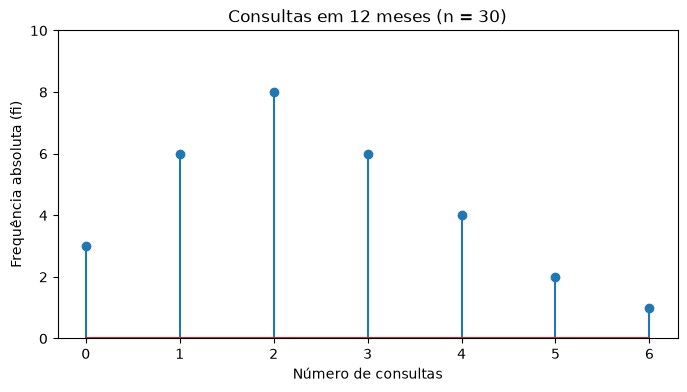

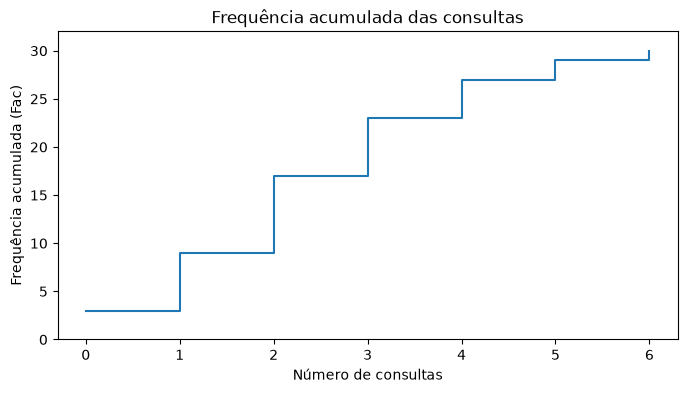

In [7]:
n = len(consultas)
fi = consultas.value_counts().sort_index()
fr = fi / n
fr_perc = fr * 100
Fac = fi.cumsum()
Fac_perc = Fac / n * 100

tab_consultas = pd.DataFrame({
    "fi": fi,
    "fr": fr,
    "fr (%)": fr_perc,
    "Fac": Fac,
    "Fac (%)": Fac_perc
})
tab_consultas.index.name = "Consultas (xi)"

display(tab_consultas)
print()
print("Soma de fi =", tab_consultas["fi"].sum(), " (n =", n, ")")
print("Última Fac =", tab_consultas["Fac"].iloc[-1])

moda = fi.idxmax()
print()
print("(a) Moda:", moda, "consultas (fi =", fi.max(), ",", round(fr_perc[moda], 1), "%)")

no_max_2 = Fac[2]
print("(b) No máximo 2 consultas:", no_max_2, "pacientes (", round(Fac_perc[2], 1), "%)")

quatro_ou_mais = fi.loc[4:].sum()
print("(c) 4 ou mais consultas:", quatro_ou_mais, "pacientes (", round(quatro_ou_mais / n * 100, 1), "%)")

plt.figure(figsize=(8, 4))
plt.stem(tab_consultas.index, tab_consultas["fi"])
plt.xlabel("Número de consultas")
plt.ylabel("Frequência absoluta (fi)")
plt.title("Consultas em 12 meses (n = 30)")
plt.ylim(0, 10)
plt.show()

plt.figure(figsize=(8, 4))
plt.step(tab_consultas.index, tab_consultas["Fac"], where="post")
plt.xlabel("Número de consultas")
plt.ylabel("Frequência acumulada (Fac)")
plt.title("Frequência acumulada das consultas")
plt.ylim(0, 32)
plt.show()

**Conclusão:**

Número de consultas é quantitativa discreta, então usei bastões (não barras coladas) e dei sentido à Fac porque os valores tem ordem.

- (a) A moda é 2 consultas (8 pacientes, 26,7%).
- (b) 17 pacientes fizeram no máximo 2 consultas, o que dá 56,7% da amostra.
- (c) Só 7 pacientes (23,3%) fizeram 4 consultas ou mais.
